# Atividade Prática — NLP 2025
## Criação de Modelo de Classificação Supervisionado para Análise de Fake News

**Disciplina:** Natural Language Processing — Uninter  
**Professor:** Prof. MSc. Guilherme Ditzel Patriota  
**RU do Aluno:** 3648752  

---

### Objetivo
Criar um modelo de classificação binária (FAKE / REAL) usando o corpus FakeBr, atingindo acurácia superior a 85%, com uso obrigatório da biblioteca NLTK e TF-IDF com bigramas e trigramas.

## 1. Importações e Downloads NLTK

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

from wordcloud import WordCloud

# Downloads NLTK necessários
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

print('Importações concluídas com sucesso!')

Matplotlib is building the font cache; this may take a moment.


Importações concluídas com sucesso!


## 2. Aquisição e Estruturação dos Dados

In [2]:
# Identificação pessoal (RU embutido no nome da variável)
RU3648752 = 3648752

# Carregar o corpus FakeBr (arquivo pre-processed.csv)
# Fonte: https://github.com/roneysco/Fake.br-Corpus
caminho_csv_3648752 = 'Fake.br-Corpus-master/preprocessed/pre-processed.csv'
df_3648752 = pd.read_csv(caminho_csv_3648752)

# Padronizar rótulos para FAKE / REAL conforme o roteiro
df_3648752['label'] = df_3648752['label'].map({'fake': 'FAKE', 'true': 'REAL'})

print(f'Shape do dataset: {df_3648752.shape}')
print(f'Colunas: {df_3648752.columns.tolist()}')
print(f'\nDistribuição dos rótulos:')
print(df_3648752['label'].value_counts())
print(f'\nPrimeiras linhas:')
df_3648752.head()

Shape do dataset: (7200, 3)
Colunas: ['index', 'label', 'preprocessed_news']

Distribuição dos rótulos:
label
FAKE    3600
REAL    3600
Name: count, dtype: int64

Primeiras linhas:


,index,label,preprocessed_news
0,0,FAKE,katia abreu diz vai colocar expulsao moldura n...
1,1,FAKE,ray peita bolsonaro conservador fake entrevist...
2,2,FAKE,reinaldo azevedo desmascarado policia federal ...
3,3,FAKE,relatorio assustador bndes mostra dinheiro pub...
4,4,FAKE,radialista americano fala sobre pt vendem ilus...


Estatísticas de palavras por classe (antes da normalização):


        count    mean     std   min     25%    50%    75%     max
label                                                            
FAKE   3600.0  107.94   72.15   5.0   67.75   92.0  130.0  1220.0
REAL   3600.0  624.94  385.43  13.0  364.00  523.0  806.0  4229.0


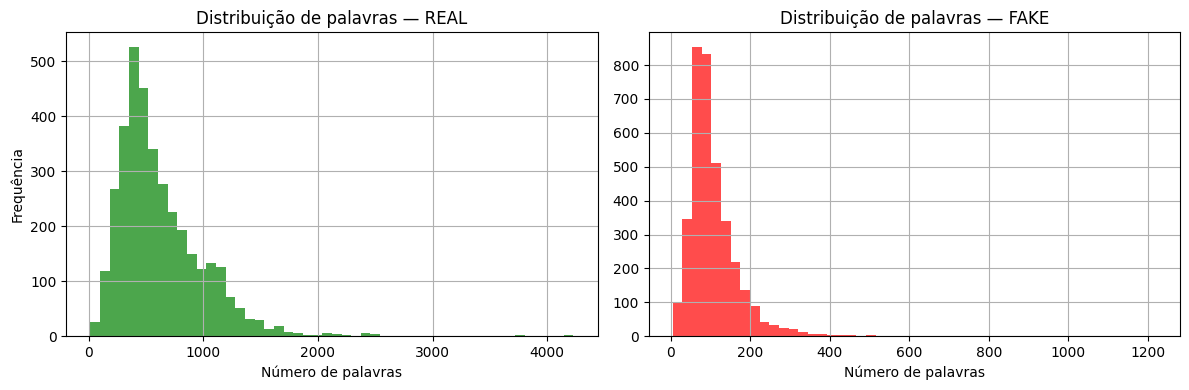

In [3]:
# Análise do tamanho dos textos por classe
df_3648752['word_count'] = df_3648752['preprocessed_news'].apply(
    lambda x: len(str(x).split())
)

print('Estatísticas de palavras por classe (antes da normalização):')
print(df_3648752.groupby('label')['word_count'].describe().round(2))

# Visualizar distribuição
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_3648752[df_3648752['label']=='REAL']['word_count'].hist(
    bins=50, ax=axes[0], color='green', alpha=0.7
)
axes[0].set_title('Distribuição de palavras — REAL')
axes[0].set_xlabel('Número de palavras')
axes[0].set_ylabel('Frequência')

df_3648752[df_3648752['label']=='FAKE']['word_count'].hist(
    bins=50, ax=axes[1], color='red', alpha=0.7
)
axes[1].set_title('Distribuição de palavras — FAKE')
axes[1].set_xlabel('Número de palavras')
plt.tight_layout()
plt.savefig('distribuicao_palavras_3648752.png', dpi=120, bbox_inches='tight')
plt.show()

## 3. Pré-Processamento

### 3.1 Normalização do tamanho dos textos

Os textos REAL possuem em média ~625 palavras, enquanto os FAKE possuem ~108 palavras. Para evitar que o modelo classifique por **tamanho** e não por **conteúdo**, os textos REAL serão truncados para a mediana do tamanho dos textos FAKE.

In [4]:
# Calcular mediana de palavras dos textos FAKE para usar como limite de truncagem
mediana_palavras_fake_3648752 = int(
    df_3648752[df_3648752['label'] == 'FAKE']['word_count'].median()
)
print(f'Mediana de palavras nos textos FAKE: {mediana_palavras_fake_3648752} palavras')
print(f'Todos os textos serão truncados para no máximo {mediana_palavras_fake_3648752} palavras.')

def truncar_texto_3648752(texto, max_palavras=mediana_palavras_fake_3648752):
    """Trunca o texto para no máximo max_palavras palavras."""
    palavras = str(texto).split()
    return ' '.join(palavras[:max_palavras])

df_3648752['texto_normalizado'] = df_3648752['preprocessed_news'].apply(
    truncar_texto_3648752
)

# Verificar normalização
df_3648752['wc_norm'] = df_3648752['texto_normalizado'].apply(lambda x: len(x.split()))
print('\nEstatísticas APÓS normalização:')
print(df_3648752.groupby('label')['wc_norm'].describe().round(2))

Mediana de palavras nos textos FAKE: 92 palavras
Todos os textos serão truncados para no máximo 92 palavras.

Estatísticas APÓS normalização:
        count   mean    std   min    25%   50%   75%   max
label                                                     
FAKE   3600.0  78.25  19.17   5.0  67.75  92.0  92.0  92.0
REAL   3600.0  91.87   2.07  13.0  92.00  92.0  92.0  92.0


### 3.2 Pré-processamento com NLTK

Técnicas aplicadas:
- **Tokenização** com `word_tokenize` (NLTK)
- **Remoção de stopwords** em português (NLTK)
- **Filtragem** de tokens não-alfabéticos e com comprimento ≤ 2 caracteres

In [5]:
# Stopwords em português (NLTK)
stopwords_pt_3648752 = set(stopwords.words('portuguese'))

print(f'Total de stopwords em português: {len(stopwords_pt_3648752)}')
print(f'Exemplos: {list(stopwords_pt_3648752)[:15]}')

def preprocessar_nltk_3648752(texto):
    """Tokeniza, remove stopwords e filtra tokens inválidos."""
    tokens = word_tokenize(str(texto), language='portuguese')
    tokens_limpos = [
        t.lower() for t in tokens
        if t.isalpha()                          # somente letras
        and t.lower() not in stopwords_pt_3648752  # sem stopwords
        and len(t) > 2                           # tamanho mínimo 3 chars
    ]
    return ' '.join(tokens_limpos)

print('\nAplicando pré-processamento NLTK (pode demorar alguns segundos)...')
df_3648752['texto_final'] = df_3648752['texto_normalizado'].apply(
    preprocessar_nltk_3648752
)
print('Pré-processamento concluído!')

print(f'\nExemplo de texto FAKE (original x processado):')
idx_exemplo = df_3648752[df_3648752['label']=='FAKE'].index[0]
print(f'Original : {df_3648752.loc[idx_exemplo, "preprocessed_news"][:150]}')
print(f'Processado: {df_3648752.loc[idx_exemplo, "texto_final"][:150]}')

Total de stopwords em português: 207
Exemplos: ['tu', 'mais', 'até', 'esteja', 'houverão', 'ser', 'fôramos', 'terá', 'hajamos', 'teus', 'em', 'teríamos', 'entre', 'nossas', 'estar']

Aplicando pré-processamento NLTK (pode demorar alguns segundos)...


Pré-processamento concluído!

Exemplo de texto FAKE (original x processado):
Original : katia abreu diz vai colocar expulsao moldura nao reclamar senadora katia abreu disse expulsao pmdb resultado acao cupula atual legenda segundo oportun
Processado: katia abreu diz vai colocar expulsao moldura nao reclamar senadora katia abreu disse expulsao pmdb resultado acao cupula atual legenda segundo oportun


## 4. Mineração — TF-IDF com Unigramas, Bigramas e Trigramas

In [6]:
# Vetorização TF-IDF com unigramas, bigramas e trigramas
tfidf_3648752 = TfidfVectorizer(
    ngram_range=(1, 3),   # unigramas, bigramas e trigramas
    max_features=50000,   # limitar para performance
    min_df=2,             # ignorar termos que aparecem em menos de 2 documentos
    sublinear_tf=True     # aplicar log(1 + tf) para suavizar frequências altas
)

X_3648752 = tfidf_3648752.fit_transform(df_3648752['texto_final'].values)
y_3648752 = df_3648752['label'].values

print(f'Shape da matriz TF-IDF: {X_3648752.shape}')
print(f'  → {X_3648752.shape[0]} documentos')
print(f'  → {X_3648752.shape[1]} features (uni + bi + trigramas)')
print(f'\nExemplos de features geradas:')
feature_names_3648752 = tfidf_3648752.get_feature_names_out()
print(f'  Unigramas: {[f for f in feature_names_3648752 if len(f.split())==1][:10]}')
print(f'  Bigramas:  {[f for f in feature_names_3648752 if len(f.split())==2][:5]}')
print(f'  Trigramas: {[f for f in feature_names_3648752 if len(f.split())==3][:5]}')

Shape da matriz TF-IDF: (7200, 50000)
  → 7200 documentos
  → 50000 features (uni + bi + trigramas)

Exemplos de features geradas:
  Unigramas: ['aaron', 'abafar', 'abaixo', 'abaixou', 'abala', 'abalada', 'abalado', 'abalar', 'abalo', 'abalou']
  Bigramas:  ['abaixo acordo', 'abaixo algumas', 'abaixo alguns', 'abaixo cbn', 'abaixo comentario']
  Trigramas: ['abaixo alguns trechos', 'abaixo detalhes sobre', 'abaixo fatos marcaram', 'abaixo grau investimento', 'abaixo integra degravacao']


## 5. Modelagem — Classificador com Regressão Logística

Divisão: **75% treino / 25% teste** (estratificado por classe)

In [7]:
# Divisão treino/teste — 75% treino, 25% teste
X_train_3648752, X_test_3648752, y_train_3648752, y_test_3648752 = train_test_split(
    X_3648752, y_3648752,
    test_size=0.25,
    random_state=42,
    stratify=y_3648752
)

print(f'Amostras de treino : {X_train_3648752.shape[0]}')
print(f'Amostras de teste  : {X_test_3648752.shape[0]}')
print(f'  FAKE treino: {(y_train_3648752 == "FAKE").sum()} | REAL treino: {(y_train_3648752 == "REAL").sum()}')
print(f'  FAKE teste : {(y_test_3648752  == "FAKE").sum()} | REAL teste : {(y_test_3648752  == "REAL").sum()}')

Amostras de treino : 5400
Amostras de teste  : 1800
  FAKE treino: 2700 | REAL treino: 2700
  FAKE teste : 900 | REAL teste : 900


In [8]:
# Treinamento do modelo — Regressão Logística
# Escolhido por ser eficiente, interpretável e com bom desempenho em classificação de texto
modelo_3648752 = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000,
    random_state=42
)

modelo_3648752.fit(X_train_3648752, y_train_3648752)

# Avaliação
y_pred_3648752 = modelo_3648752.predict(X_test_3648752)
acuracia_3648752 = accuracy_score(y_test_3648752, y_pred_3648752)

print(f'=====================================================')
print(f'  ACURÁCIA DO MODELO: {acuracia_3648752*100:.2f}%')
print(f'=====================================================')
print(f'\nRelatório completo de classificação:')
print(classification_report(y_test_3648752, y_pred_3648752))

  ACURÁCIA DO MODELO: 90.28%

Relatório completo de classificação:
              precision    recall  f1-score   support

        FAKE       0.90      0.91      0.90       900
        REAL       0.91      0.90      0.90       900

    accuracy                           0.90      1800
   macro avg       0.90      0.90      0.90      1800
weighted avg       0.90      0.90      0.90      1800



## 6. Representação — Nuvens de Palavras por Classe (TF-IDF)

Para cada classe (REAL e FAKE), calculamos a **média dos scores TF-IDF** de cada feature nos documentos daquela classe. Os termos com maior média são os mais representativos.

In [9]:
# Calcular média TF-IDF por classe (usando operações esparsas para economizar memória)
idx_real_3648752 = np.where(y_3648752 == 'REAL')[0]
idx_fake_3648752 = np.where(y_3648752 == 'FAKE')[0]

mean_tfidf_real_3648752 = np.asarray(
    X_3648752[idx_real_3648752].mean(axis=0)
).flatten()

mean_tfidf_fake_3648752 = np.asarray(
    X_3648752[idx_fake_3648752].mean(axis=0)
).flatten()

def contar_ngrams_3648752(feature_names, scores, threshold=1e-5):
    """Conta unigramas, bigramas e trigramas com score > threshold."""
    uni = sum(1 for f, s in zip(feature_names, scores) if len(f.split()) == 1 and s > threshold)
    bi  = sum(1 for f, s in zip(feature_names, scores) if len(f.split()) == 2 and s > threshold)
    tri = sum(1 for f, s in zip(feature_names, scores) if len(f.split()) == 3 and s > threshold)
    return uni, bi, tri

uni_r, bi_r, tri_r = contar_ngrams_3648752(feature_names_3648752, mean_tfidf_real_3648752)
uni_f, bi_f, tri_f = contar_ngrams_3648752(feature_names_3648752, mean_tfidf_fake_3648752)

print(f'Features com TF-IDF > 0 por classe:')
print(f'  REAL → Unigramas: {uni_r:,} | Bigramas: {bi_r:,} | Trigramas: {tri_r:,}')
print(f'  FAKE → Unigramas: {uni_f:,} | Bigramas: {bi_f:,} | Trigramas: {tri_f:,}')

Features com TF-IDF > 0 por classe:
  REAL → Unigramas: 15,924 | Bigramas: 21,229 | Trigramas: 6,305
  FAKE → Unigramas: 15,698 | Bigramas: 19,713 | Trigramas: 4,859


---
## Questão 01 — Nuvem de Palavras: Textos REAIS

**Enunciado:** Apresente o código referente ao modelo gerado e a nuvem de palavras usada para identificar textos VERDADEIROS.

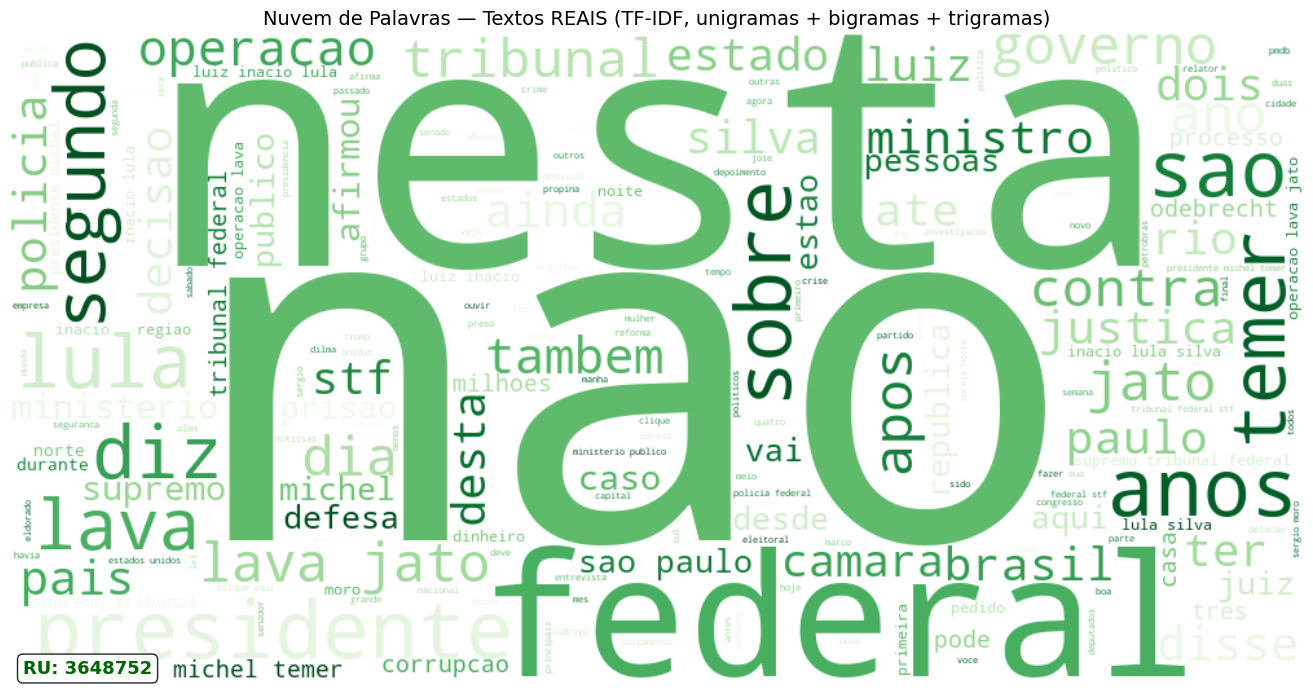

Figura salva: nuvem_real_3648752.png


In [10]:
# Frequências para WordCloud — textos REAL
freq_real_3648752 = {
    feature: float(score)
    for feature, score in zip(feature_names_3648752, mean_tfidf_real_3648752)
    if score > 1e-5
}

wc_real_3648752 = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    colormap='Greens',
    max_words=200,
    prefer_horizontal=0.8
).generate_from_frequencies(freq_real_3648752)

fig, ax = plt.subplots(figsize=(14, 7))
ax.imshow(wc_real_3648752, interpolation='bilinear')
ax.axis('off')

# Identificação pessoal na imagem (RU: 3648752)
ax.text(
    0.01, 0.01, 'RU: 3648752',
    transform=ax.transAxes, fontsize=13,
    color='darkgreen', fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85)
)

plt.title(
    'Nuvem de Palavras — Textos REAIS (TF-IDF, unigramas + bigramas + trigramas)',
    fontsize=14
)
plt.tight_layout()
plt.savefig('nuvem_real_3648752.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figura salva: nuvem_real_3648752.png')

In [11]:
# RESPOSTA Q1
print('=' * 60)
print('RESPOSTA — Questão 01')
print('=' * 60)
print(f'Textos rotulados como REAL usaram no modelo:')
print(f'  • Unigramas : {uni_r:,}')
print(f'  • Bigramas  : {bi_r:,}')
print(f'  • Trigramas : {tri_r:,}')
print(f'  • TOTAL     : {uni_r + bi_r + tri_r:,} features')
print(f'\nAcurácia do modelo: {acuracia_3648752*100:.2f}%')

RESPOSTA — Questão 01
Textos rotulados como REAL usaram no modelo:
  • Unigramas : 15,924
  • Bigramas  : 21,229
  • Trigramas : 6,305
  • TOTAL     : 43,458 features

Acurácia do modelo: 90.28%


---
## Questão 02 — Nuvem de Palavras: Textos FALSOS

**Enunciado:** Apresente o código referente ao modelo gerado e a nuvem de palavras usada para identificar textos FALSOS.

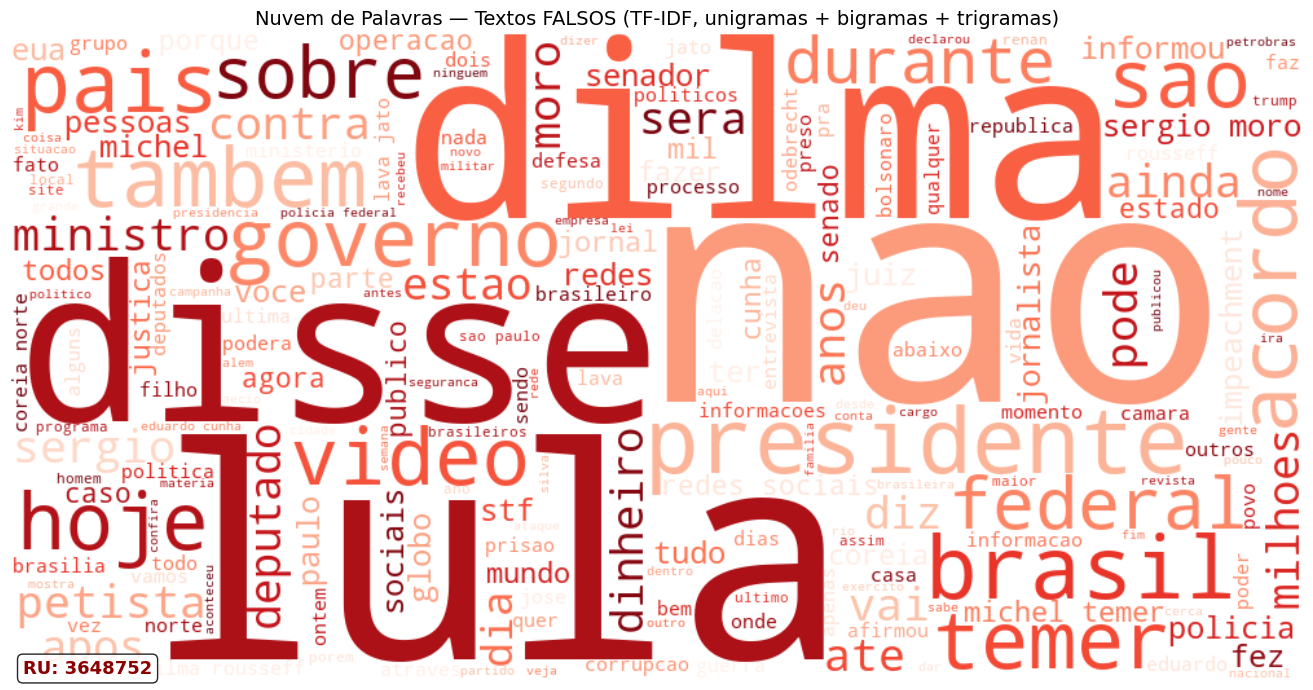

Figura salva: nuvem_fake_3648752.png


In [12]:
# Frequências para WordCloud — textos FAKE
freq_fake_3648752 = {
    feature: float(score)
    for feature, score in zip(feature_names_3648752, mean_tfidf_fake_3648752)
    if score > 1e-5
}

wc_fake_3648752 = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    colormap='Reds',
    max_words=200,
    prefer_horizontal=0.8
).generate_from_frequencies(freq_fake_3648752)

fig, ax = plt.subplots(figsize=(14, 7))
ax.imshow(wc_fake_3648752, interpolation='bilinear')
ax.axis('off')

# Identificação pessoal na imagem (RU: 3648752)
ax.text(
    0.01, 0.01, 'RU: 3648752',
    transform=ax.transAxes, fontsize=13,
    color='darkred', fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85)
)

plt.title(
    'Nuvem de Palavras — Textos FALSOS (TF-IDF, unigramas + bigramas + trigramas)',
    fontsize=14
)
plt.tight_layout()
plt.savefig('nuvem_fake_3648752.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figura salva: nuvem_fake_3648752.png')

In [13]:
# RESPOSTA Q2
print('=' * 60)
print('RESPOSTA — Questão 02')
print('=' * 60)
print(f'Textos rotulados como FAKE usaram no modelo:')
print(f'  • Unigramas : {uni_f:,}')
print(f'  • Bigramas  : {bi_f:,}')
print(f'  • Trigramas : {tri_f:,}')
print(f'  • TOTAL     : {uni_f + bi_f + tri_f:,} features')
print()
print('Técnicas de pré-processamento aplicadas:')
print('  1. Truncagem dos textos REAL para a mediana de palavras dos textos FAKE')
print('     (normalização do tamanho para evitar classificação por comprimento)')
print('  2. Tokenização com NLTK word_tokenize (Portuguese)')
print('  3. Remoção de stopwords em português (NLTK)')
print('  4. Filtragem de tokens não-alfabéticos e com ≤ 2 caracteres')
print('  5. Conversão para letras minúsculas')
print()
print('Modelo escolhido: Regressão Logística (LogisticRegression)')
print('  → Solver: liblinear')
print('  → C (regularização): 1.0')
print('  → Vetorização: TF-IDF com ngram_range=(1,3), max_features=50000')
print(f'\nAcurácia do modelo: {acuracia_3648752*100:.2f}%')

RESPOSTA — Questão 02
Textos rotulados como FAKE usaram no modelo:
  • Unigramas : 15,698
  • Bigramas  : 19,713
  • Trigramas : 4,859
  • TOTAL     : 40,270 features

Técnicas de pré-processamento aplicadas:
  1. Truncagem dos textos REAL para a mediana de palavras dos textos FAKE
     (normalização do tamanho para evitar classificação por comprimento)
  2. Tokenização com NLTK word_tokenize (Portuguese)
  3. Remoção de stopwords em português (NLTK)
  4. Filtragem de tokens não-alfabéticos e com ≤ 2 caracteres
  5. Conversão para letras minúsculas

Modelo escolhido: Regressão Logística (LogisticRegression)
  → Solver: liblinear
  → C (regularização): 1.0
  → Vetorização: TF-IDF com ngram_range=(1,3), max_features=50000

Acurácia do modelo: 90.28%


---
## Resumo Final

In [14]:
print('=' * 60)
print('  RESUMO DA ATIVIDADE PRÁTICA — NLP 2025')
print(f'  RU: {RU3648752}')
print('=' * 60)
print(f'  Dataset      : FakeBr Corpus (pre-processed.csv)')
print(f'  Total docs   : {len(df_3648752):,} (3600 FAKE + 3600 REAL)')
print(f'  Normalização : textos truncados para {mediana_palavras_fake_3648752} palavras')
print(f'  Split        : 75% treino ({X_train_3648752.shape[0]}) / 25% teste ({X_test_3648752.shape[0]})')
print(f'  Vetorização  : TF-IDF ngram(1,3) — {X_3648752.shape[1]:,} features')
print(f'  Modelo       : Regressão Logística (liblinear)')
print(f'  ACURÁCIA     : {acuracia_3648752*100:.2f}%  ✓ (meta: > 85%)')
print('=' * 60)

  RESUMO DA ATIVIDADE PRÁTICA — NLP 2025
  RU: 3648752
  Dataset      : FakeBr Corpus (pre-processed.csv)
  Total docs   : 7,200 (3600 FAKE + 3600 REAL)
  Normalização : textos truncados para 92 palavras
  Split        : 75% treino (5400) / 25% teste (1800)
  Vetorização  : TF-IDF ngram(1,3) — 50,000 features
  Modelo       : Regressão Logística (liblinear)
  ACURÁCIA     : 90.28%  ✓ (meta: > 85%)
